# Vision Transformer (ViT) — Hamiltonian Parameter Regression

**Vision Transformer** (via `keras-hub`) trained from scratch for regressing the eight
Hamiltonian parameters from $s_z$ magnetization images. Patch + self-attention encoder with a
dense regression head.


In [1]:
!pip install tensorflow --quiet
!pip install scikit-learn --quiet
!pip install pandas --quiet
!pip install matplotlib --quiet
!pip install keras-hub
print("✅ Librerías instaladas. Reinicia el kernel si vienes de una sesión con PyTorch/keras_hub cargado.")

  Using cached keras_hub-0.29.1-py3-none-any.whl.metadata (7.4 kB)
  Using cached regex-2026.6.28-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (40 kB)
  Using cached kagglehub-1.0.2-py3-none-any.whl.metadata (40 kB)
  Using cached sentencepiece-0.2.1-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (10 kB)
  Using cached tokenizers-0.23.1-cp310-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (9.8 kB)
  Using cached tensorflow_text-2.20.1-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (2.1 kB)
  Using cached kagglesdk-0.1.31-py3-none-any.whl.metadata (13 kB)
  Using cached tqdm-4.68.3-py3-none-any.whl.metadata (57 kB)
  Using cached tensorflow-2.20.0-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (4.5 kB)
  Using cached tensorboard-2.20.0-py3-none-any.whl.metadata (1.8 kB)
  Using cached markdown-3.10.2-py3-none-any.whl.metadata (5.1 kB)
  Using cached tensorboard_data

In [2]:
import keras_hub
import tensorflow as tf
from tensorflow.keras import regularizers
from tensorflow.keras.layers import Dense, GlobalAveragePooling1D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

2026-06-30 18:26:00.169946: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-30 18:26:00.240619: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-06-30 18:26:01.767134: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [3]:
import os
import warnings
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TF: {tf.__version__}")
print(f"GPUs: {tf.config.list_physical_devices('GPU')}")

TF: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
DATASET_PATH = "/workspace/Preprocess/latent_space_outputs/dataset_final_estructuras.npz"

data = np.load(DATASET_PATH, allow_pickle=True)
print("Keys:", data.files)

X = np.copy(data['img'])
y = np.copy(data['params'])
label_names = np.copy(data['label_names'])

print(f"\nX shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"X rango: [{X.min():.3f}, {X.max():.3f}]")
print(f"y rango: [{y.min():.3f}, {y.max():.3f}]")

print("\nDistribución por estructura:")
unique, counts_lbl = np.unique(label_names, return_counts=True)
for u, c in zip(unique, counts_lbl):
    print(f"  {u:15s}: {c:>8,}  ({100*c/len(label_names):.1f}%)")

Keys: ['img', 'params', 'cluster_id', 'label_names']

X shape: (166141, 39, 39, 1)
y shape: (166141, 8)
X rango: [-1.000, 1.000]
y rango: [-0.331, 20.000]

Distribución por estructura:
  Bimerones      :    6,395  (3.8%)
  Ising          :    1,487  (0.9%)
  Others         :   25,310  (15.2%)
  Skyrmiones     :   12,841  (7.7%)
  helical        :  120,108  (72.3%)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.1765, random_state=SEED
)

print(f"Train: {X_train.shape[0]:>8,}  ({100*X_train.shape[0]/len(X):.1f}%)")
print(f"Val:   {X_val.shape[0]:>8,}  ({100*X_val.shape[0]/len(X):.1f}%)")
print(f"Test:  {X_test.shape[0]:>8,}  ({100*X_test.shape[0]/len(X):.1f}%)")

Train:  116,293  (70.0%)
Val:     24,926  (15.0%)
Test:    24,922  (15.0%)


In [6]:
scaler = MinMaxScaler()
y_train_scaled = scaler.fit_transform(y_train)
y_val_scaled   = scaler.transform(y_val)
y_test_scaled  = scaler.transform(y_test)

print("Scaler ajustado sobre y_train")
print(f"  rango original: [{y_train.min():.4f}, {y_train.max():.4f}]")
print(f"  rango scaled:   [{y_train_scaled.min():.4f}, {y_train_scaled.max():.4f}]")

Scaler ajustado sobre y_train
  rango original: [-0.3310, 20.0000]
  rango scaled:   [0.0000, 1.0000]


In [7]:
def preprocess_batch(x):
    x = tf.image.resize(x, (224, 224))
    x = tf.image.grayscale_to_rgb(x)
    return x

BATCH_SIZE = 512

train_dataset = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train_scaled))
    .shuffle(10000, seed=SEED)
    .batch(BATCH_SIZE)
    .map(lambda x, y: (preprocess_batch(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)
val_dataset = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val_scaled))
    .batch(BATCH_SIZE)
    .map(lambda x, y: (preprocess_batch(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)
test_dataset = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test_scaled))
    .batch(BATCH_SIZE)
    .map(lambda x, y: (preprocess_batch(x), y), num_parallel_calls=tf.data.AUTOTUNE)
    .prefetch(tf.data.AUTOTUNE)
)

print(f"Train batches: {len(train_dataset)}")
print(f"Val batches:   {len(val_dataset)}")
print(f"Test batches:  {len(test_dataset)}")

I0000 00:00:1782844053.846629     202 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 140841 MB memory:  -> device: 0, name: NVIDIA H200, pci bus id: 0000:3a:00.0, compute capability: 9.0


Train batches: 228
Val batches:   49
Test batches:  49


In [8]:
# Backbone
backbone = keras_hub.models.ViTBackbone.from_preset(
    "vit_base_patch16_224_imagenet"
)

inputs = tf.keras.Input(shape=(224, 224, 3))
x = backbone(inputs)

# Colapsar tokens
x = GlobalAveragePooling1D()(x)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)
x = Dense(256, activation="relu",
          kernel_regularizer=regularizers.l2(1e-4))(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)

outputs = Dense(8, activation="linear")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="mse",
    metrics=["mae"]
)

model.summary()

100%|██████████| 909/909 [00:00<00:00, 1.44MB/s]


100%|██████████| 328M/328M [00:15<00:00, 21.9MB/s] 


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vi_t_backbone (ViTBackbone)     │ (None, 197, 768)       │    85,798,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 768)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 768)            │         3,072 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       196,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         2,056 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 86,001,672 (328.07 MB)

 Trainable params: 85,999,624 (328.06 MB)

 Non-trainable params: 2,048 (8.00 KB)

In [9]:
EPOCHS = 40

early_stop = EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', factor=0.3, patience=4, min_lr=1e-6
)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/40


2026-06-30 18:29:39.973997: I external/local_xla/xla/service/service.cc:163] XLA service 0x7d78b40031e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-06-30 18:29:39.974035: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA H200, Compute Capability 9.0
2026-06-30 18:29:46.312217: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-06-30 18:29:56.119572: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002
2026-06-30 18:30:05.410074: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_252', 8 bytes spill stores, 8 bytes spill loads

2026-06-30 18:30:07.616369: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Regis

227/228 ━━━━━━━━━━━━━━━━━━━━ 0s 572ms/step - loss: 1.1906 - mae: 0.8124

2026-06-30 18:32:44.825165: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-06-30 18:32:51.516300: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_23283', 76 bytes spill stores, 76 bytes spill loads

2026-06-30 18:32:51.627875: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_22986', 76 bytes spill stores, 76 bytes spill loads

2026-06-30 18:32:51.821582: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_22986', 10

228/228 ━━━━━━━━━━━━━━━━━━━━ 0s 688ms/step - loss: 1.1904 - mae: 0.8123

2026-06-30 18:33:24.108824: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_599', 224 bytes spill stores, 224 bytes spill loads

2026-06-30 18:33:24.159599: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_73', 364 bytes spill stores, 364 bytes spill loads

2026-06-30 18:33:24.232994: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_72', 12 bytes spill stores, 12 bytes spill loads

2026-06-30 18:33:24.285929: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_5', 4 bytes spill stores, 4 bytes spill loads

2026-06-30 18:33:24.372922: I external/local_x

228/228 ━━━━━━━━━━━━━━━━━━━━ 250s 788ms/step - loss: 1.1904 - mae: 0.8123 - val_loss: 0.1240 - val_mae: 0.2467 - learning_rate: 1.0000e-04
Epoch 2/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 133s 581ms/step - loss: 0.7350 - mae: 0.6264 - val_loss: 0.0791 - val_mae: 0.1552 - learning_rate: 1.0000e-04
Epoch 3/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 124s 542ms/step - loss: 0.5502 - mae: 0.5292 - val_loss: 0.0729 - val_mae: 0.1345 - learning_rate: 1.0000e-04
Epoch 4/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 121s 528ms/step - loss: 0.4228 - mae: 0.4506 - val_loss: 0.0569 - val_mae: 0.0987 - learning_rate: 1.0000e-04
Epoch 5/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 116s 508ms/step - loss: 0.3294 - mae: 0.3891 - val_loss: 0.0527 - val_mae: 0.0839 - learning_rate: 1.0000e-04
Epoch 6/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 116s 508ms/step - loss: 0.2563 - mae: 0.3341 - val_loss: 0.0505 - val_mae: 0.0761 - learning_rate: 1.0000e-04
Epoch 7/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 115s 504ms/step - loss: 0.2019 - mae: 0.2876 - val_loss: 0.0484 - val_m

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



228/228 ━━━━━━━━━━━━━━━━━━━━ 117s 513ms/step - loss: 0.0065 - mae: 0.0356 - val_loss: 0.0130 - val_mae: 0.0438 - learning_rate: 1.0000e-04
Epoch 37/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 116s 507ms/step - loss: 0.0053 - mae: 0.0338 - val_loss: 0.0126 - val_mae: 0.0444 - learning_rate: 1.0000e-04
Epoch 38/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 116s 509ms/step - loss: 0.0043 - mae: 0.0320 - val_loss: 0.0112 - val_mae: 0.0417 - learning_rate: 1.0000e-04
Epoch 39/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 121s 528ms/step - loss: 0.0034 - mae: 0.0302 - val_loss: 0.0108 - val_mae: 0.0424 - learning_rate: 1.0000e-04
Epoch 40/40
228/228 ━━━━━━━━━━━━━━━━━━━━ 123s 536ms/step - loss: 0.0028 - mae: 0.0286 - val_loss: 0.0108 - val_mae: 0.0418 - learning_rate: 1.0000e-04


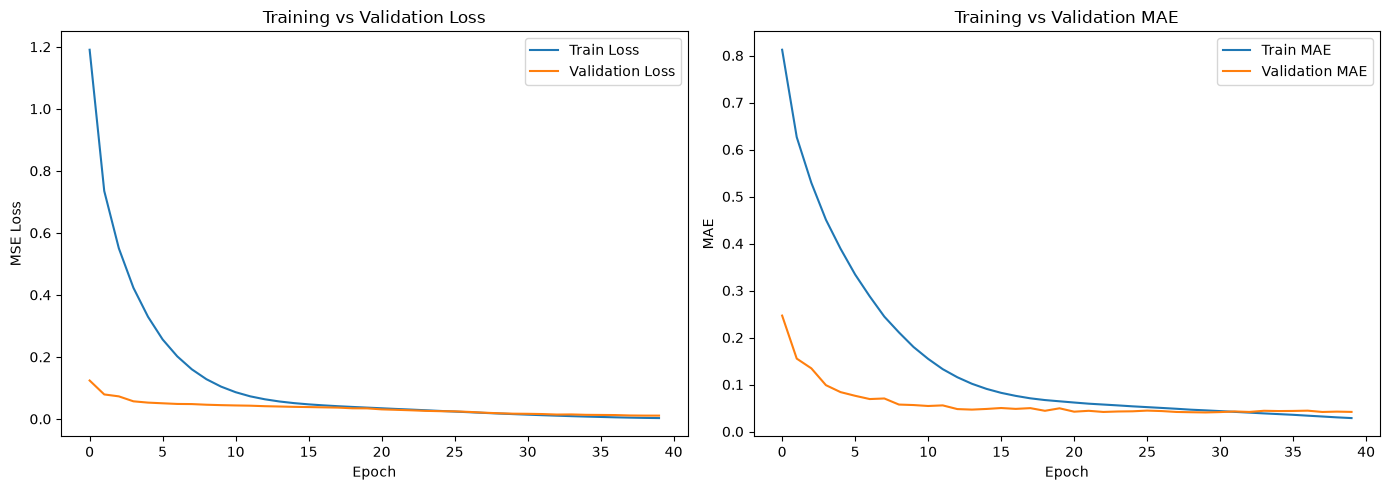

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history['loss'], label='Train Loss')
axes[0].plot(history.history['val_loss'], label='Validation Loss')
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].legend()

axes[1].plot(history.history['mae'], label='Train MAE')
axes[1].plot(history.history['val_mae'], label='Validation MAE')
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("MAE")
axes[1].set_title("Training vs Validation MAE")
axes[1].legend()

plt.tight_layout()
plt.savefig("/workspace/Models/Inverse/Images/vit_baseline_curves.png", dpi=150, bbox_inches='tight')
plt.show()

In [11]:
y_pred_scaled = model.predict(test_dataset)
y_pred = scaler.inverse_transform(y_pred_scaled)
y_true = scaler.inverse_transform(y_test_scaled)

param_names = ["T", "Jex2", "Jex3", "Jex4", "Kan1", "KanS", "Hex", "KDM"]

rows = []
for i, name in enumerate(param_names):
    mae  = mean_absolute_error(y_true[:, i], y_pred[:, i])
    rmse = np.sqrt(mean_squared_error(y_true[:, i], y_pred[:, i]))
    r2   = r2_score(y_true[:, i], y_pred[:, i])
    rows.append({"Parameter": name, "MAE": round(mae,4), "RMSE": round(rmse,4), "R²": round(r2,4)})

df_metrics = pd.DataFrame(rows).set_index("Parameter").sort_values("R²", ascending=False)
print(df_metrics.to_string())

48/49 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step

2026-06-30 19:53:37.446538: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_581', 224 bytes spill stores, 224 bytes spill loads

2026-06-30 19:53:37.537287: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_73', 364 bytes spill stores, 364 bytes spill loads

2026-06-30 19:53:37.628265: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 4 bytes spill stores, 4 bytes spill loads

2026-06-30 19:53:37.736735: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_72', 12 bytes spill stores, 12 bytes spill loads

2026-06-30 19:53:37.746173: I external/local_xla

49/49 ━━━━━━━━━━━━━━━━━━━━ 25s 370ms/step
              MAE    RMSE      R²
Parameter                        
KDM        0.0367  0.0453  0.9860
Hex        0.0123  0.0177  0.9667
T          0.3877  0.6949  0.9509
Kan1       0.0549  0.0924  0.9241
Jex2       0.0177  0.0472  0.8874
KanS       0.0274  0.0379  0.6292
Jex3       0.0317  0.0833 -0.2946
Jex4       0.0250  0.0660 -0.3021


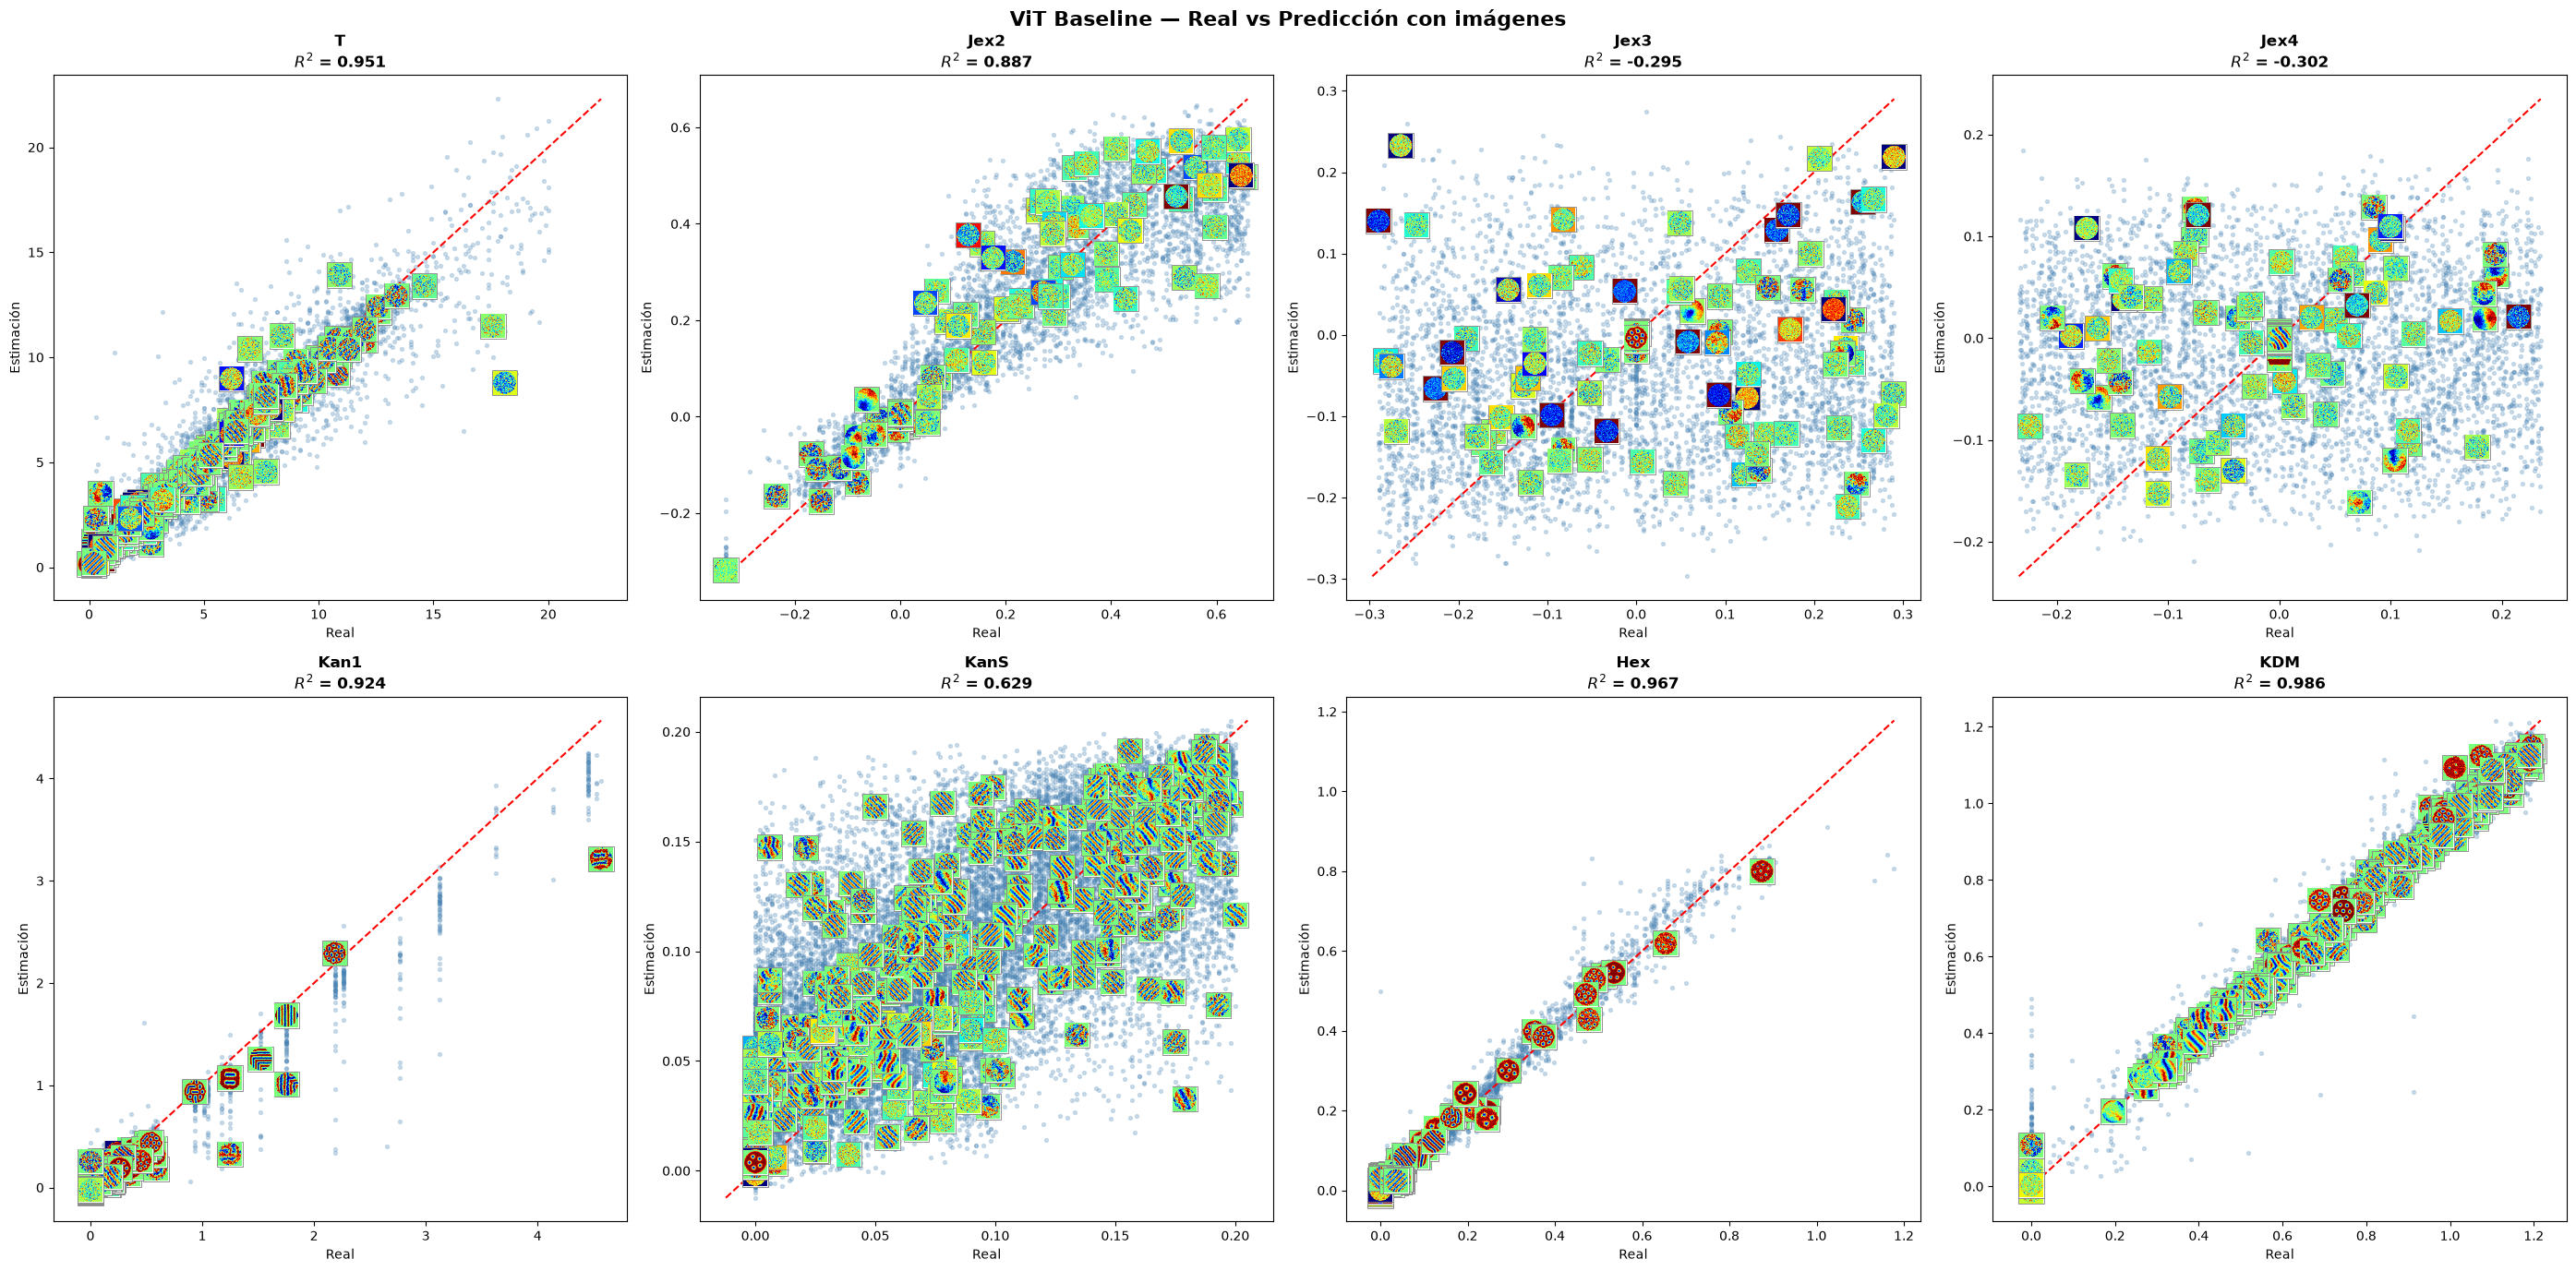

In [12]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

n_outputs = y_true.shape[1]
fig, axes = plt.subplots(2, 4, figsize=(28, 14))
axes = axes.flatten()

N_THUMBS = 400
rng = np.random.RandomState(SEED)

for i in range(n_outputs):
    ax = axes[i]
    name = param_names[i]

    ax.scatter(y_true[:, i], y_pred[:, i], alpha=0.25, s=8, color="steelblue")

    lims = [min(y_true[:,i].min(), y_pred[:,i].min()),
            max(y_true[:,i].max(), y_pred[:,i].max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5)

    # thumbnails — muestra aleatoria simple
    idx_thumbs = rng.choice(len(y_true), size=N_THUMBS, replace=False)

    for idx in idx_thumbs:
        img = X_test[idx, :, :, 0]
        norm_img = (img - img.min()) / (img.max() - img.min() + 1e-8)
        colored = plt.cm.jet(norm_img)[:, :, :3]
        imagebox = OffsetImage(colored, zoom=0.48)
        ab = AnnotationBbox(
            imagebox,
            (y_true[idx, i], y_pred[idx, i]),
            frameon=True,
            bboxprops=dict(edgecolor='gray', linewidth=0.6),
            pad=0.05,
            zorder=3
        )
        ax.add_artist(ab)

    r2 = r2_score(y_true[:, i], y_pred[:, i])
    ax.set_title(f"{name}\n$R^2$ = {r2:.3f}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Real")
    ax.set_ylabel("Estimación")

plt.suptitle("ViT Baseline — Real vs Predicción con imágenes",
             fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig("/workspace/Models/Inverse/Images/vit_real_vs_pred_thumbs.png",
            dpi=140, bbox_inches="tight")
plt.show()

In [13]:
SAVE_DIR = "/workspace/Models/Inverse/ModelWeights"
os.makedirs(SAVE_DIR, exist_ok=True)

model.save(f"{SAVE_DIR}/modelo_vit_baseline_estructuras.keras")
print(f"Modelo guardado en {SAVE_DIR}/modelo_vit_baseline_estructuras.keras")

import pickle
with open(f"{SAVE_DIR}/scaler_vit_baseline.pkl", 'wb') as f:
    pickle.dump(scaler, f)
print("Scaler guardado.")

Modelo guardado en /workspace/Models/Inverse/ModelWeights/modelo_vit_baseline_estructuras.keras
Scaler guardado.
